# Машинное обучение, ФКН ВШЭ

# Практическое задание 6. Бустинговое

## Общая информация

Дата выдачи: 12.12.2024

Мягкий дедлайн: 22.12.2024 23:59 MSK

Жёсткий дедлайн: 22.12.2024 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-06-Username.ipynb

Username — ваша фамилия на латинице

## О задании

В этом задании вам предстоит вручную запрограммировать один из самых мощных алгоритмов машинного обучения — бустинг. Однако с большой силой приходит и большая ответственность, так что заодно научимся, как его правильно готовить

In [ ]:
from warnings import filterwarnings

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.sparse import load_npz
from sklearn.model_selection import train_test_split

sns.set(style='darkgrid')
filterwarnings('ignore')

In [ ]:
X = load_npz('x.npz')
y = np.load('y.npy')

Разделим на обучающую, валидационную и тестовую выборки (оставьте `random_state=1337` для воспроизводимости).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1337)
X_test, X_valid, y_test, y_valid = train_test_split(X_test, y_test, test_size=0.5, random_state=1337)

X_train.shape, X_valid.shape, X_test.shape

((18825, 169), (2354, 169), (2353, 169))

---

## Задание 1. Базовый градиентный бустинг (4 балла)

Первая часть посвящена реализации собственного градиентного бустинга. Обращаем внимание, что пользоваться готовыми реализациями <font color='lightcoral'>**нельзя**</font>, если специально не оговорено. На все <font color='plum'>**вопросы**</font> должен быть <font color='plum'>**ответ**</font>. В заданиях есть референсы для параметров, которые нужно сделать, на случай, если объяснение из ноутбука непонятно, тогда советуем обратиться к соответствующей документации

Вам нужно дописать код в файлике `boosting.py`. Для вас уже подготовлен шаблон класса `Boosting`, вы можете менять его по своему усмотрению.

### Инструкции для функций:

#### `__init__`

Обязательные параметры:
 — `base_model_class` — класс базовой модели нашего бустинга
 — `base_model_params` — словарь с гиперпараметрами для базовой модели
 — `n_estimators` — какое количество базовых моделей нужно обучить
 — `learning_rate` — темп обучения, должен быть из полуинтервала $(0, 1]$

#### `fit`

В `fit` приходит выборка, на которой мы обучаем новые базовые модели

Сначала нам нужно сделать какую-то нулевую модель, сделать предсказания (в шаблоне это нулевая модель, соответственно предсказания это просто `np.zeros`). После этого нужно обучить `n_estimators` базовых моделей (как и на что обучаются базовые модели смотрите в лекциях и семинарах). После каждой обученной базовой модели мы должны обновить текущие предсказания, посчитать ошибку на выборке (используем `loss_fn` для этого) и найти новую оптимальную гамму

После всего цикла обучения надо нарисовать график (если `plot=True`).

#### `partial_fit`

В `partial_fit` приходит обучающая выборка, на которую обучается новая базовая модель

#### `predict_proba`

В `predict_proba` приходит любая выборка, нужно предсказать вероятности для неё. Суммируем предсказания базовых моделей на этой выборке (не забываем про гаммы) и накидываем сигмоиду

#### `plot_history`

В `plot_history` приходит любая выборка, для которой последовательно считаются значения функции потерь и/или любой метрики, которую вы хотите посчитать, путем последовательного применения базовых моделей. Можно делать сразу во время обучения, можно делать иначе

In [ ]:
from __future__ import annotations

from collections import defaultdict

import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeRegressor

from typing import Optional


def score(clf, x, y):
    return roc_auc_score(y == 1, clf.predict_proba(x)[:, 1])


class Boosting:

    def __init__(
        self,
        base_model_class = DecisionTreeRegressor,
        base_model_params: Optional[dict] = None,
        n_estimators: int = 10,
        learning_rate: float = 0.1,
    ):
        self.base_model_class = base_model_class
        self.base_model_params: dict = {} if base_model_params is None else base_model_params

        self.n_estimators: int = n_estimators

        self.models: list = []
        self.gammas: list = []

        self.learning_rate: float = learning_rate

        self.history = defaultdict(list) # {"train_roc_auc": [], "train_loss": [], ...}

        self.sigmoid = lambda x: 1 / (1 + np.exp(-x))
        self.loss_fn = lambda y, z: -np.log(self.sigmoid(y * z)).mean()
        self.loss_derivative = lambda y, z: -y * (1 - self.sigmoid(y * z))  # Исправьте формулу на правильную.

    def partial_fit(self, X, y):
        gradient = self.loss_derivative(y, self.train_predictions)

        model = self.base_model_class(**self.base_model_params)
        model.fit(X, -gradient)

        new_pred = model.predict(X)

        gamma = self.find_optimal_gamma(y, self.train_predictions, new_pred)

        self.models.append(model)
        self.gammas.append(gamma)

        self.train_predictions += self.learning_rate * gamma * new_pred

    def fit(self, X_train, y_train, X_val=None, y_val=None, plot=False):
        """
        :param X_train: features array (train set)
        :param y_train: targets array (train set)
        :param X_val: features array (eval set)
        :param y_val: targets array (eval set)
        :param plot: bool
        """
        self.train_predictions = np.zeros(y_train.shape[0])

        for _ in range(self.n_estimators):
            self.partial_fit(X_train, y_train)

            train_loss = self.loss_fn(y_train, self.train_predictions)
            self.history["train_loss"].append(train_loss)

            train_proba = self.sigmoid(self.train_predictions)
            train_roc = roc_auc_score(y_train == 1, train_proba)
            self.history["train_roc_auc"].append(train_roc)

            if X_val is not None:
                model = self.models[-1]
                gamma = self.gammas[-1]
                val_pred = model.predict(X_val)
                self.val_predictions += self.learning_rate * gamma * val_pred

                val_loss = self.loss_fn(y_val, self.val_predictions)
                self.history["val_loss"].append(val_loss)

                val_proba = self.sigmoid(self.val_predictions)
                val_roc = roc_auc_score(y_val == 1, val_proba)
                self.history["val_roc_auc"].append(val_roc)

        if plot:
            self.plot_history(X_train, y_train)

    def predict_proba(self, X):
        pred = np.zeros(X.shape[0])

        for model, gamma in zip(self.models, self.gammas):
            pred += self.learning_rate * gamma * model.predict(X)
        proba = self.sigmoid(pred)
        return np.column_stack([1 - proba, proba])

    def find_optimal_gamma(self, y, old_predictions, new_predictions) -> float:
        gammas = np.linspace(start=0, stop=1, num=100)
        losses = [self.loss_fn(y, old_predictions + gamma * new_predictions) for gamma in gammas]
        return gammas[np.argmin(losses)]

    def score(self, X, y):
        return score(self, X, y)

    def plot_history(self, X, y):
        """
        :param X: features array (any set)
        :param y: targets array (any set)
        """
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 2, 1)
        plt.plot(self.history["train_loss"], label="train")
        plt.title("Loss")
        plt.xlabel("Iteration")
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(self.history["train_roc_auc"], label="train")
        plt.title("ROC AUC")
        plt.xlabel("Iteration")
        plt.legend()

        plt.tight_layout()
        plt.show()

In [ ]:
# %load_ext autoreload

In [ ]:
# %autoreload 2

# from boosting import Boosting

### Проверка кода

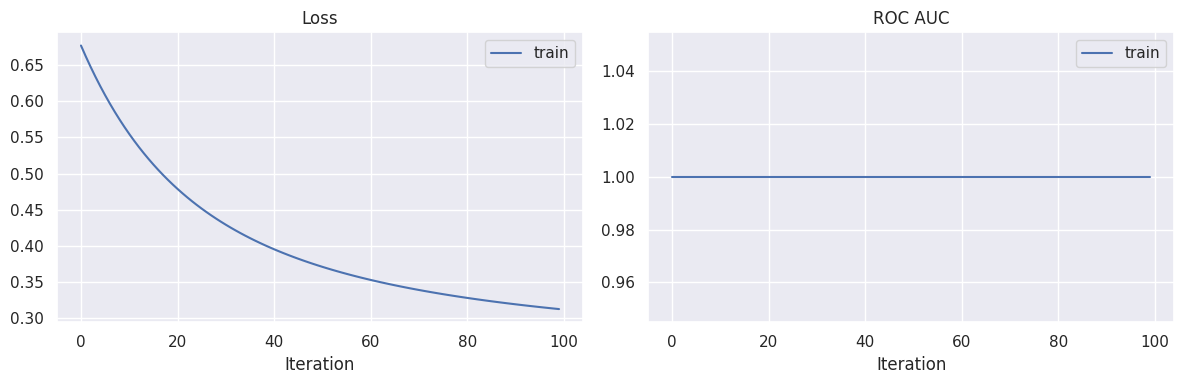

Train ROC-AUC 0.9998
Valid ROC-AUC 0.9082
Test ROC-AUC 0.9034


In [ ]:
boosting = Boosting(n_estimators=100)

boosting.fit(X_train, y_train)
boosting.plot_history(X_valid, y_valid)

assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)

print(f'Train ROC-AUC {boosting.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {boosting.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {boosting.score(X_test, y_test):.4f}')

---

## Задание 2. Имплементация гиперпараметров (2.5 балла + 3.5 бонус)

Бустинг, как метод агрегации, предлагает несколько вариантов регуляризации безотносительно базовой модели. В этом пункте предлагается имплементировать часть из них. При необходимости можете обратиться к реализациям в вашей любимой библиотеке, там могут быть дополнительные пояснения и/или ссылки на оригинальные статьи

<font color='lightcoral'>**Важно!**</font> После добавления каждого параметра проверьте, как это повлияет на качество. Специально крутить параметры не нужно, но важно увидеть, что перформанс модели изменился, в худшую или в лучшую сторону, для этого какие-то параметры нужны, пусть и от балды, <font color='lightcoral'>**дефолтные параметры не подойдут**</font>, они скорее для референса. Лучше всего это видно по графикам обучения <font color='lightcoral'>**на трейне и валидации**</font>, рекомендуется смотрить именно на них

### 2.1. Борьба с переобучением (0.5 балла)

Как известно, бустинги бывают склонны к переобучению. Чтобы этого не допустить, можно контролировать процесс обучения и проверять критерий останова на валидации. Реализуйте такую процедуру, не забудьте, что всю предобработку, что вы будете делать для трейна, нужно будет повторить на валидации

| <font color='lightblue'>XGBoost</font> | <font color='lightgreen'>LightGBM</font> | <font color='palegoldenrod'>CatBoost</font> |
| --- | --- | --- |
| <td colspan=3>`early_stopping_rounds`, `eval_set` |

Добавьте параметры:
- `early_stopping_rounds: int | None = 0` — число раундов для критерия останова. Если качество ухудшается на протяжении всех раундов подряд, останавливаем обучение
- `X_val`, `y_val` или `eval_set: Tuple[np.ndarray] | None = None` — валидацонная выборка, на которой будем проверять переобучение

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚
from typing import Optional, Tuple

class Boosting:

    def __init__(
        self,
        base_model_class=DecisionTreeRegressor,
        base_model_params: Optional[dict] = None,
        n_estimators: int = 10,
        learning_rate: float = 0.1,
        early_stopping_rounds: int = 0,
    ):
        self.base_model_class = base_model_class
        self.base_model_params: dict = {} if base_model_params is None else base_model_params

        self.n_estimators: int = n_estimators
        self.learning_rate: float = learning_rate
        self.early_stopping_rounds = early_stopping_rounds

        self.models: list = []
        self.gammas: list = []
        self.history = defaultdict(list)

        self.sigmoid = lambda x: 1 / (1 + np.exp(-x))
        self.loss_fn = lambda y, z: -np.log(self.sigmoid(y * z)).mean()
        self.loss_derivative = lambda y, z: -y * (1 - self.sigmoid(y * z))

        self.best_val_loss = np.inf
        self.best_iter = 0
        self.best_models = []
        self.best_gammas = []

    def partial_fit(self, X, y):
        gradient = self.loss_derivative(y, self.train_predictions)

        model = self.base_model_class(**self.base_model_params)
        model.fit(X, -gradient)

        new_pred = model.predict(X)
        gamma = self.find_optimal_gamma(y, self.train_predictions, new_pred)

        self.models.append(model)
        self.gammas.append(gamma)

        self.train_predictions += self.learning_rate * gamma * new_pred

    def fit(self,X_train, y_train,X_val=None, y_val=None,eval_set: Optional[Tuple[np.ndarray, np.ndarray]] = None,plot=False):
        if eval_set is not None:
            X_val, y_val = eval_set[0], eval_set[1]

        self.train_predictions = np.zeros(y_train.shape[0])
        if X_val is not None:
            self.val_predictions = np.zeros(y_val.shape[0])

        for n_iter in range(self.n_estimators):
            self.partial_fit(X_train, y_train)

            train_loss = self.loss_fn(y_train, self.train_predictions)
            self.history["train_loss"].append(train_loss)

            train_proba = self.sigmoid(self.train_predictions)
            train_roc = roc_auc_score(y_train == 1, train_proba)
            self.history["train_roc_auc"].append(train_roc)

            if X_val is not None:
                model = self.models[-1]
                gamma = self.gammas[-1]
                val_pred = model.predict(X_val)
                self.val_predictions += self.learning_rate * gamma * val_pred

                val_loss = self.loss_fn(y_val, self.val_predictions)
                self.history["val_loss"].append(val_loss)

                val_proba = self.sigmoid(self.val_predictions)
                val_roc = roc_auc_score(y_val == 1, val_proba)
                self.history["val_roc_auc"].append(val_roc)

                if self.early_stopping_rounds > 0:
                    if val_loss < self.best_val_loss:
                        self.best_val_loss = val_loss
                        self.best_iter = n_iter
                        self.best_models = self.models.copy()
                        self.best_gammas = self.gammas.copy()
                    elif n_iter - self.best_iter >= self.early_stopping_rounds:
                        self.models = self.best_models
                        self.gammas = self.best_gammas
                        break

        if self.early_stopping_rounds > 0 and self.best_iter < n_iter:
            self.train_predictions = np.zeros(X_train.shape[0])
            for model, gamma in zip(self.models, self.gammas):
                self.train_predictions += self.learning_rate * gamma * model.predict(X_train)

            if X_val is not None:
                self.val_predictions = np.zeros(X_val.shape[0])
                for model, gamma in zip(self.models, self.gammas):
                    self.val_predictions += self.learning_rate * gamma * model.predict(X_val)

        if plot:
            self.plot_history(X_train, y_train)

        return self

    def predict_proba(self, X):
        raw_pred = np.zeros(X.shape[0])
        for model, gamma in zip(self.models, self.gammas):
            raw_pred += self.learning_rate * gamma * model.predict(X)
        proba = self.sigmoid(raw_pred)
        return np.column_stack([1 - proba, proba])

    def find_optimal_gamma(self, y, old_predictions, new_predictions) -> float:
        gammas = np.linspace(start=0, stop=1, num=100)
        losses = [self.loss_fn(y, old_predictions + gamma * new_predictions) for gamma in gammas]
        return gammas[np.argmin(losses)]

    def score(self, X, y):
        return score(self, X, y)

    def plot_history(self, X, y):
        import matplotlib.pyplot as plt

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 2, 1)
        plt.plot(self.history["train_loss"], label="train")
        if "val_loss" in self.history:
            plt.plot(self.history["val_loss"], label="val")
        plt.title("Loss")
        plt.xlabel("Iteration")
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(self.history["train_roc_auc"], label="train")
        if "val_roc_auc" in self.history:
            plt.plot(self.history["val_roc_auc"], label="val")
        plt.title("ROC AUC")
        plt.xlabel("Iteration")
        plt.legend()

        plt.tight_layout()
        plt.show()

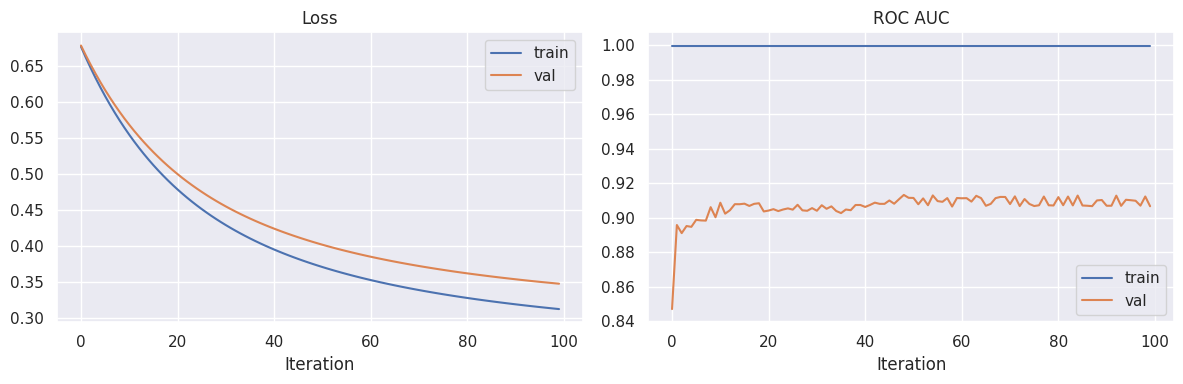

Train ROC-AUC 0.9998
Valid ROC-AUC 0.9067
Test ROC-AUC 0.9043


In [ ]:
boosting = Boosting(n_estimators=100)

boosting.fit(X_train, y_train, X_valid, y_valid)
boosting.plot_history(X_valid, y_valid)

assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)

print(f'Train ROC-AUC {boosting.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {boosting.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {boosting.score(X_test, y_test):.4f}')

### 2.2. Бутстрап (0.5 балла)
Как известно, при обучении базовых алгоритмов в беггинге, используется бутстрапированная выборка. Звучит хайпово, почему бы не попробовать сделать то же самое в бустинге?

| <font color='lightblue'>XGBoost</font> | <font color='lightgreen'>LightGBM</font> | <font color='palegoldenrod'>CatBoost</font> |
| --- | --- | --- |
| `subsample`, — | `subsample`, `bagging`| `subsample`, `bootstrap_type`|

Вам нужно реализовать параметры:
- `subsample: float | int = 1.0` — доля или число объектов, на которой будет обучаться базовая модель (какую часть составляет бутстрапная выборка от исходной обучающей). Соответствует бутстрапу типа `Bernoulli`. Каждый объект либо входит в подвыборку, либо нет
- `bagging_temperature: float | int = 1.0` — веса объектов, которые попадают в выборку. Соответствует бутстрапу типа `Bayesian`. Каждый объект имеет определенный вес $t$, на который впоследствии домножается по формуле $w = (-\log(X))^t$, где $X \sim {U[0, 1]}$, после чего попадает в выборку. Таким образом можно сделать симуляцию повторений
- `bootstrap_type: str | None = 'Bernoulli'` — тип бутстрапа

<font color='plum'>**Вопрос:** как бутстрап может помочь в обучении с точки зрения смещения, разброса и вообще?</font>

<font color='plum'>**Ответ:** ... </font>

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚
class Boosting:

    def __init__(
        self,
        base_model_class=DecisionTreeRegressor,
        base_model_params: Optional[dict] = None,
        n_estimators: int = 10,
        learning_rate: float = 0.1,
        early_stopping_rounds: int = 0,
        subsample: float = 0.5,
        bagging_temperature: float = 1.0,
        bootstrap_type: Optional[str] = 'Bernoulli',
    ):
        self.base_model_class = base_model_class
        self.base_model_params: dict = {} if base_model_params is None else base_model_params

        self.n_estimators: int = n_estimators
        self.learning_rate: float = learning_rate
        self.early_stopping_rounds = early_stopping_rounds
        self.subsample = subsample
        self.bagging_temperature = bagging_temperature
        self.bootstrap_type = bootstrap_type

        self.models: list = []
        self.gammas: list = []
        self.history = defaultdict(list)

        self.sigmoid = lambda x: 1 / (1 + np.exp(-x))
        self.loss_fn = lambda y, z: -np.log(self.sigmoid(y * z)).mean()
        self.loss_derivative = lambda y, z: -y * (1 - self.sigmoid(y * z))

        self.train_predictions = None
        self.val_predictions = None


        self.best_val_loss = np.inf
        self.best_iter = 0
        self.best_models = []
        self.best_gammas = []

    def _get_bootstrap_sample(self, n_samples: int):
        """
        Возвращает индексы/веса объектов в соответствии с типом бутстрапа.
        """
        if self.bootstrap_type is None or self.subsample == 1.0:
            return None, None

        if self.subsample <= 1.0:
            p = self.subsample
        else:
            p = min(self.subsample / n_samples, 1.0)

        if self.bootstrap_type == 'Bernoulli':
            mask = np.random.binomial(1, p, size=n_samples).astype(bool)
            idx = np.where(mask)[0]
            return idx, None
        elif self.bootstrap_type == 'Bayesian':
            U = np.random.uniform(low=1e-12, high=1.0, size=n_samples)
            weights = (-np.log(U)) ** self.bagging_temperature
            return np.arange(n_samples), weights
        else:
            raise ValueError(f"Unknown bootstrap_type: {self.bootstrap_type}")

    def partial_fit(self, X, y):
        if self.train_predictions is None:
            raise RuntimeError("You must call fit() first to initialize train_predictions.")

        gradient = self.loss_derivative(y, self.train_predictions)

        idx, weights = self._get_bootstrap_sample(len(y))

        model = self.base_model_class(**self.base_model_params)

        if idx is None:
            model.fit(X, -gradient)
        else:
            model.fit(X[idx], -gradient[idx])

        new_pred = model.predict(X)
        gamma = self.find_optimal_gamma(y, self.train_predictions, new_pred)

        self.models.append(model)
        self.gammas.append(gamma)

        self.train_predictions += self.learning_rate * gamma * new_pred

    def fit(
        self,
        X_train, y_train,
        X_val=None, y_val=None,
        eval_set: Optional[Tuple[np.ndarray, np.ndarray]] = None,
        plot=False
    ):
        if eval_set is not None:
            X_val, y_val = eval_set[0], eval_set[1]

        self.train_predictions = np.zeros(y_train.shape[0])
        self.val_predictions = np.zeros(y_val.shape[0]) if X_val is not None else None


        for n_iter in range(self.n_estimators):
            self.partial_fit(X_train, y_train)

            train_loss = self.loss_fn(y_train, self.train_predictions)
            self.history["train_loss"].append(train_loss)

            train_proba = self.sigmoid(self.train_predictions)
            train_roc = roc_auc_score(y_train == 1, train_proba)
            self.history["train_roc_auc"].append(train_roc)

            if X_val is not None:
                model = self.models[-1]
                gamma = self.gammas[-1]
                val_pred = model.predict(X_val)
                self.val_predictions += self.learning_rate * gamma * val_pred

                val_loss = self.loss_fn(y_val, self.val_predictions)
                self.history["val_loss"].append(val_loss)

                val_proba = self.sigmoid(self.val_predictions)
                val_roc = roc_auc_score(y_val == 1, val_proba)
                self.history["val_roc_auc"].append(val_roc)

                if self.early_stopping_rounds > 0:
                    if val_loss < self.best_val_loss:
                        self.best_val_loss = val_loss
                        self.best_iter = n_iter
                        self.best_models = self.models.copy()
                        self.best_gammas = self.gammas.copy()
                    elif n_iter - self.best_iter >= self.early_stopping_rounds:
                        print(f"Early stopping at iteration {n_iter}, "
                              f"best iteration was {self.best_iter}")
                        self.models = self.best_models
                        self.gammas = self.best_gammas
                        break

        if self.early_stopping_rounds > 0 and self.best_iter < n_iter:
            self.train_predictions = np.zeros(X_train.shape[0])
            for model, gamma in zip(self.models, self.gammas):
                self.train_predictions += self.learning_rate * gamma * model.predict(X_train)

            if X_val is not None:
                self.val_predictions = np.zeros(X_val.shape[0])
                for model, gamma in zip(self.models, self.gammas):
                    self.val_predictions += self.learning_rate * gamma * model.predict(X_val)

        if plot:
            self.plot_history(X_train, y_train)

        return self

    def predict_proba(self, X):
        raw_pred = np.zeros(X.shape[0])
        for model, gamma in zip(self.models, self.gammas):
            raw_pred += self.learning_rate * gamma * model.predict(X)
        proba = self.sigmoid(raw_pred)
        return np.column_stack([1 - proba, proba])

    def find_optimal_gamma(self, y, old_predictions, new_predictions) -> float:
        gammas = np.linspace(start=0, stop=1, num=100)
        losses = [self.loss_fn(y, old_predictions + gamma * new_predictions) for gamma in gammas]
        return gammas[np.argmin(losses)]

    def score(self, X, y):
        return score(self, X, y)

    def plot_history(self, X, y):
        import matplotlib.pyplot as plt

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 2, 1)
        plt.plot(self.history["train_loss"], label="train")
        if "val_loss" in self.history:
            plt.plot(self.history["val_loss"], label="val")
        plt.title("Loss")
        plt.xlabel("Iteration")
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(self.history["train_roc_auc"], label="train")
        if "val_roc_auc" in self.history:
            plt.plot(self.history["val_roc_auc"], label="val")
        plt.title("ROC AUC")
        plt.xlabel("Iteration")
        plt.legend()

        plt.tight_layout()
        plt.show()

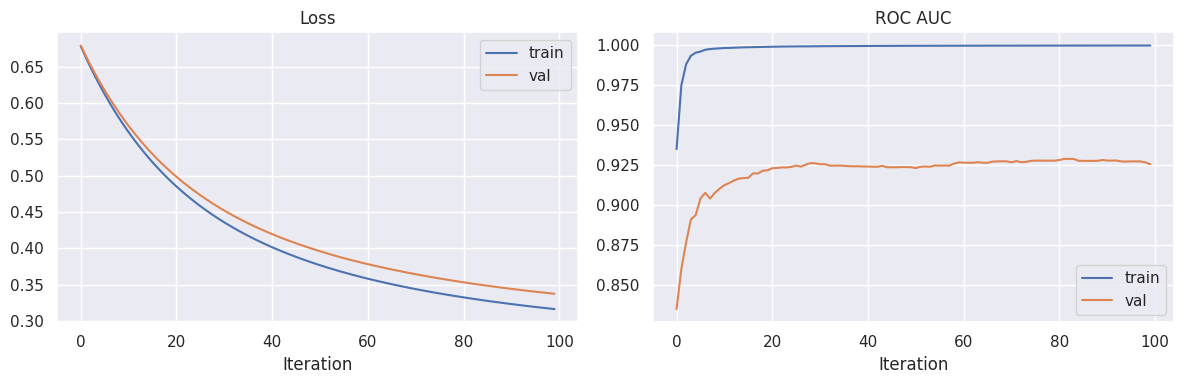

Train ROC-AUC 0.9996
Valid ROC-AUC 0.9254
Test ROC-AUC 0.9220


In [ ]:
boosting = Boosting(n_estimators=100)

boosting.fit(X_train, y_train, X_valid, y_valid)
boosting.plot_history(X_valid, y_valid)

assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)

print(f'Train ROC-AUC {boosting.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {boosting.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {boosting.score(X_test, y_test):.4f}')

### 2.3. Работа с признаками (1 балл)

1. Помимо выбора случайных объектов, есть идея выбирать случайное подмножество признаков, заложенная в Random Forest. Мотивация это делать точно та же самая, что и в бутстрапировании, за это будет отвечать `rsm`

2. С другой стороны, вместо того, чтобы выкидывать признаки, можно попробовать проредить их множество значений, применив бинаризацию. В идеале это стоит делать с датасетом до обучения модели, но не обязательно, можно, например, на этапе `fit`, а в `partial_fit` приходит уже квантизованный датасет. Для этого существует множество алгоритмов, мы предлагаем сделать два наиболее простых:

- $\text{Uniform}$. Значения признака $[\min f_i, \max f_i]$ отображаются в `nbins` отрезков одинаковой длины, которые полностью покрывают интервал
- $\text{Quantile}$. Тот же самый отрезок сортируется и бьется на `nbins` квантилей от 0 до 1

| <font color='lightblue'>XGBoost</font> | <font color='lightgreen'>LightGBM</font> | <font color='palegoldenrod'>CatBoost</font> |
| --- | --- | --- |
| `colsample_bytree`, `tree_method` | `colsample_bytree`, `max_bin`| `rsm`, `quantize(...)`|

Нужно добавить параметры:
- `rsm: float | int = 1.0` — доля или число признаков, участвующих в обучении модели. Каждый признак либо входит, либо не входит в пул, на котором обучается базовый алгоритм, по аналогии с бутстрапом Бернулли
- `quantization_type: str | None = None` — тип квантизации, если она есть
- `nbins: int = 255` — число бинов для квантизации. Игнорируем, если тип квантизации не указан

<font color='plum'>**Вопрос**: как квантизация поможет в обработке выбросов и нанов?</font>

<font color='plum'>**Ответ**: ... </font>

<font color='plum'>**Вопрос**: можно ли просто заполнить наны каким-то числом? Имеет ли значение, что это за число (-1, -100, -1e32)?</font>

<font color='plum'>**Ответ**: ... </font>

In [ ]:
from scipy.sparse import issparse
class Boosting:

    def __init__(
        self,
        base_model_class=DecisionTreeRegressor,
        base_model_params: Optional[dict] = None,
        n_estimators: int = 10,
        learning_rate: float = 0.1,
        early_stopping_rounds: int = 0,
        subsample: float = 1.0,
        bagging_temperature: float = 1.0,
        bootstrap_type: Optional[str] = 'Bernoulli',
        rsm: float = 0.7,
        quantization_type: Optional[str] = 'Uniform',# 'Uniform', 'Quantile' или None
        nbins: int = 255,# число бинов
    ):
        self.base_model_class = base_model_class
        self.base_model_params: dict = {} if base_model_params is None else base_model_params

        self.n_estimators: int = n_estimators
        self.learning_rate: float = learning_rate
        self.early_stopping_rounds = early_stopping_rounds
        self.subsample = subsample
        self.bagging_temperature = bagging_temperature
        self.bootstrap_type = bootstrap_type
        self.rsm = rsm
        self.quantization_type = quantization_type
        self.nbins = nbins

        self.models: list = []
        self.gammas: list = []
        self.history = defaultdict(list)

        self.sigmoid = lambda x: 1 / (1 + np.exp(-x))
        self.loss_fn = lambda y, z: -np.log(self.sigmoid(y * z)).mean()
        self.loss_derivative = lambda y, z: -y * (1 - self.sigmoid(y * z))

        self.train_predictions = None
        self.val_predictions = None

        self.best_val_loss = np.inf
        self.best_iter = 0
        self.best_models = []
        self.best_gammas = []

        self._bin_edges = None


    def _fit_quantizer(self, X: np.ndarray):
        if self.quantization_type is None:
            self._bin_edges = None
            return

        n_features = X.shape[1]
        self._bin_edges = []
        for j in range(n_features):
            col = X[:, j]
            if self.quantization_type == 'Uniform':
                min_val, max_val = col.min(), col.max()
                edges = np.linspace(min_val, max_val, self.nbins + 1)
                edges[0] = -np.inf
                edges[-1] = np.inf
                self._bin_edges.append(edges)

            elif self.quantization_type == 'Quantile':
                quantiles = np.linspace(0, 1, self.nbins + 1)
                edges = np.quantile(col, quantiles)
                edges[0] = -np.inf
                edges[-1] = np.inf
                edges = np.unique(edges)
                self._bin_edges.append(edges)

    def _quantize(self, X: np.ndarray) -> np.ndarray:
        X = self._to_dense(X)
        if self._bin_edges is None:
            return X
        n_samples, n_features = X.shape
        X_binned = np.empty_like(X, dtype=int)
        for j in range(n_features):
            edges = self._bin_edges[j]
            X_binned[:, j] = np.digitize(X[:, j], edges, right=True)
        return X_binned

    def _get_bootstrap_sample(self, n_samples: int):
        if self.bootstrap_type is None or self.subsample == 1.0:
            return None, None

        p = self.subsample if self.subsample <= 1.0 else min(self.subsample / n_samples, 1.0)

        if self.bootstrap_type == 'Bernoulli':
            mask = np.random.binomial(1, p, size=n_samples).astype(bool)
            idx = np.where(mask)[0]
            return idx, None

    def _get_rsm_features(self, n_features: int) -> np.ndarray:
        if self.rsm == 1.0:
            return np.arange(n_features)

        if self.rsm <= 1.0:
            mask = np.random.binomial(1, self.rsm, size=n_features).astype(bool)
        else:
            n_selected = min(int(self.rsm), n_features)
            idx = np.random.choice(n_features, size=n_selected, replace=False)
            mask = np.zeros(n_features, dtype=bool)
            mask[idx] = True
        return np.where(mask)[0]

    def partial_fit(self, X, y):
        X = self._to_dense(X)
        gradient = self.loss_derivative(y, self.train_predictions)

        idx, weights = self._get_bootstrap_sample(len(y))

        feature_indices = self._get_rsm_features(X.shape[1])

        model = self.base_model_class(**self.base_model_params)

        X_sub = X[:, feature_indices] if len(feature_indices) < X.shape[1] else X

        if idx is None:
            model.fit(X_sub, -gradient)
        else:
            if self.bootstrap_type == 'Bernoulli':
                model.fit(X_sub[idx], -gradient[idx])

        new_pred = model.predict(X_sub)

        gamma = self.find_optimal_gamma(y, self.train_predictions, new_pred)

        self.models.append((model, feature_indices))
        self.gammas.append(gamma)

        self.train_predictions += self.learning_rate * gamma * new_pred

    def fit(
        self,
        X_train, y_train,
        X_val=None, y_val=None,
        eval_set: Optional[Tuple[np.ndarray, np.ndarray]] = None,
        plot=False
    ):
        if eval_set is not None:
            X_val, y_val = eval_set[0], eval_set[1]

        X_train = self._to_dense(X_train)
        if X_val is not None:
            X_val = self._to_dense(X_val)


        self._fit_quantizer(X_train)
        X_train_q = self._quantize(X_train)
        if X_val is not None:
            X_val_q = self._quantize(X_val)

        self.train_predictions = np.zeros(y_train.shape[0])
        self.val_predictions = np.zeros(y_val.shape[0]) if X_val is not None else None


        for n_iter in range(self.n_estimators):
            self.partial_fit(X_train_q, y_train)

            train_loss = self.loss_fn(y_train, self.train_predictions)
            self.history["train_loss"].append(train_loss)

            train_proba = self.sigmoid(self.train_predictions)
            train_roc = roc_auc_score(y_train == 1, train_proba)
            self.history["train_roc_auc"].append(train_roc)

            if X_val is not None:
                model, feat_idx = self.models[-1]
                gamma = self.gammas[-1]
                val_pred = model.predict(X_val_q[:, feat_idx] if len(feat_idx) < X_val_q.shape[1] else X_val_q)
                self.val_predictions += self.learning_rate * gamma * val_pred

                val_loss = self.loss_fn(y_val, self.val_predictions)
                self.history["val_loss"].append(val_loss)

                val_proba = self.sigmoid(self.val_predictions)
                val_roc = roc_auc_score(y_val == 1, val_proba)
                self.history["val_roc_auc"].append(val_roc)

                if self.early_stopping_rounds > 0:
                    if val_loss < self.best_val_loss:
                        self.best_val_loss = val_loss
                        self.best_iter = n_iter
                        self.best_models = self.models.copy()
                        self.best_gammas = self.gammas.copy()
                    elif n_iter - self.best_iter >= self.early_stopping_rounds:
                        print(f"Early stopping at iteration {n_iter}, "
                              f"best iteration was {self.best_iter}")
                        self.models = self.best_models
                        self.gammas = self.best_gammas
                        break

        if self.early_stopping_rounds > 0 and self.best_iter < n_iter:
            self.train_predictions = np.zeros(X_train_q.shape[0])
            for (model, feat_idx), gamma in zip(self.models, self.gammas):
                X_sub = X_train_q[:, feat_idx] if len(feat_idx) < X_train_q.shape[1] else X_train_q
                self.train_predictions += self.learning_rate * gamma * model.predict(X_sub)

            if X_val is not None:
                self.val_predictions = np.zeros(X_val_q.shape[0])
                for (model, feat_idx), gamma in zip(self.models, self.gammas):
                    X_sub = X_val_q[:, feat_idx] if len(feat_idx) < X_val_q.shape[1] else X_val_q
                    self.val_predictions += self.learning_rate * gamma * model.predict(X_sub)

        if plot:
            self.plot_history(X_train, y_train)

        return self

    def predict_proba(self, X):
        X_q = self._quantize(X)
        raw_pred = np.zeros(X_q.shape[0])
        for (model, feat_idx), gamma in zip(self.models, self.gammas):
            X_sub = X_q[:, feat_idx] if len(feat_idx) < X_q.shape[1] else X_q
            raw_pred += self.learning_rate * gamma * model.predict(X_sub)
        proba = self.sigmoid(raw_pred)
        return np.column_stack([1 - proba, proba])

    @staticmethod
    def _to_dense(X):
        if issparse(X):
            return X.toarray()
        elif hasattr(X, 'toarray'):
            return X.toarray()
        return np.asarray(X)

    def find_optimal_gamma(self, y, old_predictions, new_predictions) -> float:
        gammas = np.linspace(start=0, stop=1, num=100)
        losses = [self.loss_fn(y, old_predictions + gamma * new_predictions) for gamma in gammas]
        return gammas[np.argmin(losses)]

    def score(self, X, y):
        return score(self, X, y)

    def plot_history(self, X, y):
        import matplotlib.pyplot as plt
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(self.history["train_loss"], label="train")
        if "val_loss" in self.history:
            plt.plot(self.history["val_loss"], label="val")
        plt.title("Loss")
        plt.xlabel("Iteration")
        plt.legend()
        plt.subplot(1, 2, 2)
        plt.plot(self.history["train_roc_auc"], label="train")
        if "val_roc_auc" in self.history:
            plt.plot(self.history["val_roc_auc"], label="val")
        plt.title("ROC AUC")
        plt.xlabel("Iteration")
        plt.legend()
        plt.tight_layout()
        plt.show()

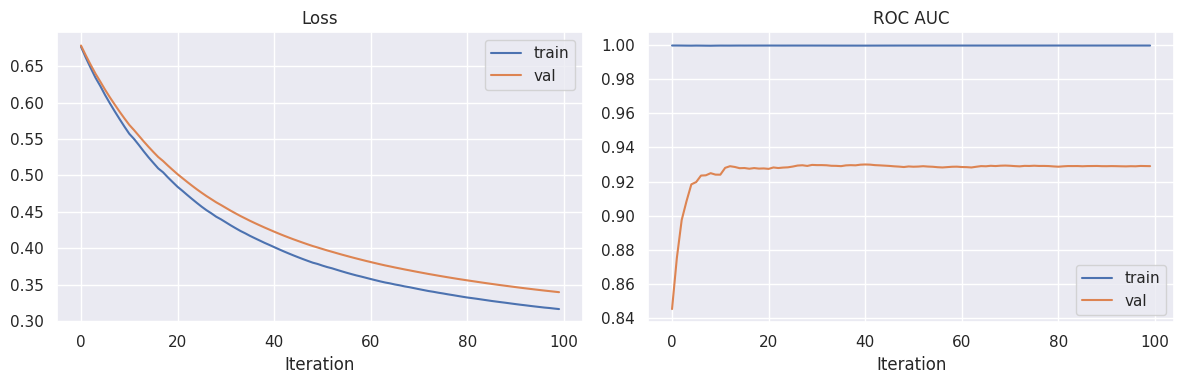

Train ROC-AUC 0.9998
Valid ROC-AUC 0.9290
Test ROC-AUC 0.9253


In [ ]:
boosting = Boosting(n_estimators=100)

boosting.fit(X_train, y_train, X_valid, y_valid)
boosting.plot_history(X_valid, y_valid)

assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)

print(f'Train ROC-AUC {boosting.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {boosting.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {boosting.score(X_test, y_test):.4f}')

### 2.4. Важность признаков (0.5 балла)

Поскольку наша базовая модель — это дерево из `sklearn`, мы можем вычислить важность признака отдельно для каждого дерева и усреднить (воспользуйтесь `feature_importances_` у `DecisionTreeRegressor`), после этого нормировать значения, чтобы они суммировались в единицу (обратите внимание, что они должны быть неотрицательными — иначе вы что-то сделали не так). Разумеется, способ не единственный, если хочется, посмотрите в документации

| <font color='lightblue'>XGBoost</font> | <font color='lightgreen'>LightGBM</font> | <font color='palegoldenrod'>CatBoost</font> |
| --- | --- | --- |
| `model.get_score()` | `lightgbm.importance()` | `model.get_feature_importance()` |

Допишите к бустингу:
- `feature_importances_` — атрибут, который возвращает важность признаков, согласно методу выше

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚
class Boosting:
    def __init__(
        self,
        base_model_class=DecisionTreeRegressor,
        base_model_params: Optional[dict] = None,
        n_estimators: int = 10,
        learning_rate: float = 0.1,
        early_stopping_rounds: int = 0,
        subsample: float = 1.0,
        bagging_temperature: float = 1.0,
        bootstrap_type: Optional[str] = 'Bernoulli',
        rsm: float = 0.7,
        quantization_type: Optional[str] = 'Uniform',
        nbins: int = 255,
    ):
        self.base_model_class = base_model_class
        self.base_model_params: dict = {} if base_model_params is None else base_model_params
        self.n_estimators: int = n_estimators
        self.learning_rate: float = learning_rate
        self.early_stopping_rounds = early_stopping_rounds
        self.subsample = subsample
        self.bagging_temperature = bagging_temperature
        self.bootstrap_type = bootstrap_type
        self.rsm = rsm
        self.quantization_type = quantization_type
        self.nbins = nbins

        self.models: list = []
        self.gammas: list = []
        self.history = defaultdict(list)

        self.sigmoid = lambda x: 1 / (1 + np.exp(-x))
        self.loss_fn = lambda y, z: -np.log(self.sigmoid(y * z)).mean()
        self.loss_derivative = lambda y, z: -y * (1 - self.sigmoid(y * z))

        self.train_predictions = None
        self.val_predictions = None

        self.best_val_loss = np.inf
        self.best_iter = 0
        self.best_models = []
        self.best_gammas = []

        self._bin_edges = None
        self.n_features_ = None

    @staticmethod
    def _to_dense(X):
        if issparse(X):
            return X.toarray()
        if hasattr(X, 'toarray'):
            return X.toarray()
        return np.asarray(X)

    def _fit_quantizer(self, X: np.ndarray):
        if self.quantization_type is None:
            self._bin_edges = None
            return
        n_features = X.shape[1]
        self._bin_edges = []
        for j in range(n_features):
            col = X[:, j]
            if self.quantization_type == 'Uniform':
                min_val, max_val = col.min(), col.max()
                edges = np.linspace(min_val, max_val, self.nbins + 1)
                edges[0] = -np.inf
                edges[-1] = np.inf
                self._bin_edges.append(edges)
            elif self.quantization_type == 'Quantile':
                quantiles = np.linspace(0, 1, self.nbins + 1)
                edges = np.quantile(col, quantiles)
                edges[0] = -np.inf
                edges[-1] = np.inf
                edges = np.unique(edges)
                self._bin_edges.append(edges)

    def _quantize(self, X: np.ndarray) -> np.ndarray:
        if self._bin_edges is None:
            return X
        X = self._to_dense(X)
        n_samples, n_features = X.shape
        X_binned = np.empty_like(X, dtype=int)
        for j in range(n_features):
            edges = self._bin_edges[j]
            X_binned[:, j] = np.digitize(X[:, j], edges, right=True)
        return X_binned

    def _get_bootstrap_sample(self, n_samples: int):
        if self.bootstrap_type is None or self.subsample == 1.0:
            return None, None
        p = self.subsample if self.subsample <= 1.0 else min(self.subsample / n_samples, 1.0)
        if self.bootstrap_type == 'Bernoulli':
            mask = np.random.binomial(1, p, size=n_samples).astype(bool)
            idx = np.where(mask)[0]
            return idx, None
        return None, None

    def _get_rsm_features(self, n_features: int) -> np.ndarray:
        if self.rsm == 1.0:
            return np.arange(n_features)
        if self.rsm <= 1.0:
            mask = np.random.binomial(1, self.rsm, size=n_features).astype(bool)
        else:
            n_selected = min(int(self.rsm), n_features)
            idx = np.random.choice(n_features, size=n_selected, replace=False)
            mask = np.zeros(n_features, dtype=bool)
            mask[idx] = True
        return np.where(mask)[0]

    def partial_fit(self, X, y):
        X = self._to_dense(X)
        gradient = self.loss_derivative(y, self.train_predictions)
        idx, weights = self._get_bootstrap_sample(len(y))
        feature_indices = self._get_rsm_features(X.shape[1])
        model = self.base_model_class(**self.base_model_params)
        X_sub = X[:, feature_indices] if len(feature_indices) < X.shape[1] else X

        if idx is None:
            model.fit(X_sub, -gradient)
        else:
            if self.bootstrap_type == 'Bernoulli':
                model.fit(X_sub[idx], -gradient[idx])

        new_pred = model.predict(X_sub)
        gamma = self.find_optimal_gamma(y, self.train_predictions, new_pred)

        self.models.append((model, feature_indices))
        self.gammas.append(gamma)
        self.train_predictions += self.learning_rate * gamma * new_pred

    def fit(self, X_train, y_train, X_val=None, y_val=None,
            eval_set=None, plot=False):
        if eval_set is not None:
            X_val, y_val = eval_set[0], eval_set[1]

        X_train = self._to_dense(X_train)
        if X_val is not None:
            X_val = self._to_dense(X_val)

        self.n_features_ = X_train.shape[1]

        self._fit_quantizer(X_train)
        X_train_q = self._quantize(X_train)
        X_val_q = self._quantize(X_val) if X_val is not None else None

        self.train_predictions = np.zeros(y_train.shape[0])
        self.val_predictions = np.zeros(y_val.shape[0]) if X_val is not None else None

        for n_iter in range(self.n_estimators):
            self.partial_fit(X_train_q, y_train)

            train_loss = self.loss_fn(y_train, self.train_predictions)
            self.history["train_loss"].append(train_loss)
            train_proba = self.sigmoid(self.train_predictions)
            self.history["train_roc_auc"].append(roc_auc_score(y_train == 1, train_proba))

            if X_val_q is not None:
                model, feat_idx = self.models[-1]
                gamma = self.gammas[-1]
                X_val_sub = X_val_q[:, feat_idx] if len(feat_idx) < X_val_q.shape[1] else X_val_q
                val_pred = model.predict(X_val_sub)
                self.val_predictions += self.learning_rate * gamma * val_pred

                val_loss = self.loss_fn(y_val, self.val_predictions)
                self.history["val_loss"].append(val_loss)
                val_proba = self.sigmoid(self.val_predictions)
                self.history["val_roc_auc"].append(roc_auc_score(y_val == 1, val_proba))

                if self.early_stopping_rounds > 0:
                    if val_loss < self.best_val_loss:
                        self.best_val_loss = val_loss
                        self.best_iter = n_iter
                        self.best_models = self.models.copy()
                        self.best_gammas = self.gammas.copy()
                    elif n_iter - self.best_iter >= self.early_stopping_rounds:
                        print(f"Early stopping at iteration {n_iter}, "
                              f"best iteration was {self.best_iter}")
                        self.models = self.best_models
                        self.gammas = self.best_gammas
                        break

        if self.early_stopping_rounds > 0 and self.best_iter < n_iter:
            self.train_predictions = np.zeros(X_train_q.shape[0])
            for (model, feat_idx), gamma in zip(self.models, self.gammas):
                X_sub = X_train_q[:, feat_idx] if len(feat_idx) < X_train_q.shape[1] else X_train_q
                self.train_predictions += self.learning_rate * gamma * model.predict(X_sub)
            if X_val_q is not None:
                self.val_predictions = np.zeros(X_val_q.shape[0])
                for (model, feat_idx), gamma in zip(self.models, self.gammas):
                    X_sub = X_val_q[:, feat_idx] if len(feat_idx) < X_val_q.shape[1] else X_val_q
                    self.val_predictions += self.learning_rate * gamma * model.predict(X_sub)

        if plot:
            self.plot_history(X_train, y_train)
        return self

    def predict_proba(self, X):
        X = self._to_dense(X)
        X_q = self._quantize(X)
        raw_pred = np.zeros(X_q.shape[0])
        for (model, feat_idx), gamma in zip(self.models, self.gammas):
            X_sub = X_q[:, feat_idx] if len(feat_idx) < X_q.shape[1] else X_q
            raw_pred += self.learning_rate * gamma * model.predict(X_sub)
        proba = self.sigmoid(raw_pred)
        return np.column_stack([1 - proba, proba])

    def find_optimal_gamma(self, y, old_predictions, new_predictions) -> float:
        gammas = np.linspace(start=0, stop=1, num=100)
        losses = [self.loss_fn(y, old_predictions + gamma * new_predictions) for gamma in gammas]
        return gammas[np.argmin(losses)]

    def score(self, X, y):
        return score(self, X, y)

    @property
    def feature_importances_(self):
        n_features = self.n_features_
        total_importance = np.zeros(n_features)
        for model, feat_idx in self.models:
            total_importance[feat_idx] += model.feature_importances_
        avg_importance = total_importance / len(self.models)
        s = avg_importance.sum()
        if s > 0:
            avg_importance /= s
        return avg_importance

    def plot_history(self, X, y):
        import matplotlib.pyplot as plt
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(self.history["train_loss"], label="train")
        if "val_loss" in self.history:
            plt.plot(self.history["val_loss"], label="val")
        plt.title("Loss")
        plt.xlabel("Iteration")
        plt.legend()
        plt.subplot(1, 2, 2)
        plt.plot(self.history["train_roc_auc"], label="train")
        if "val_roc_auc" in self.history:
            plt.plot(self.history["val_roc_auc"], label="val")
        plt.title("ROC AUC")
        plt.xlabel("Iteration")
        plt.legend()
        plt.tight_layout()
        plt.show()

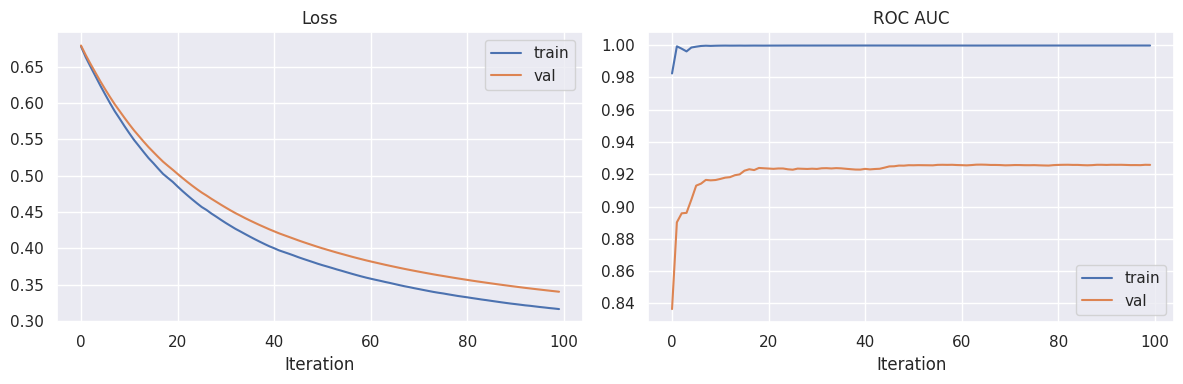

Train ROC-AUC 0.9998
Valid ROC-AUC 0.9258
Test ROC-AUC 0.9242


In [ ]:
boosting = Boosting(n_estimators=100)

boosting.fit(X_train, y_train, X_valid, y_valid)
boosting.plot_history(X_valid, y_valid)

assert len(boosting.models) == boosting.n_estimators
assert len(boosting.gammas) == boosting.n_estimators

assert boosting.predict_proba(X_test).shape == (X_test.shape[0], 2)

print(f'Train ROC-AUC {boosting.score(X_train, y_train):.4f}')
print(f'Valid ROC-AUC {boosting.score(X_valid, y_valid):.4f}')
print(f'Test ROC-AUC {boosting.score(X_test, y_test):.4f}')

Покажите, какие признаки оказались самыми важными

In [ ]:
# *𖣂♱𖠰𖣂↟*𖠰ᨒ↟*𖥧˚
print(boosting.feature_importances_)

[2.59108789e-03 6.11588898e-03 6.33478573e-03 1.59119489e-03
 1.88442706e-03 2.70471034e-03 9.70755283e-04 9.05283964e-04
 7.46980111e-04 3.26362757e-03 6.05554131e-03 1.16153680e-03
 1.86997600e-03 2.48758335e-04 5.04632715e-04 1.72542885e-03
 4.35213760e-05 4.54908054e-04 3.44557660e-04 2.46028995e-03
 6.78404810e-03 4.17751649e-03 2.10936620e-03 1.60836891e-03
 7.14738885e-03 3.22718543e-03 6.21409173e-04 5.99188147e-03
 5.38712406e-04 7.34094957e-04 1.95953750e-03 1.99337731e-03
 9.24989427e-04 6.30807011e-04 1.04932428e-03 2.33105152e-03
 1.30955528e-02 2.29569494e-03 1.88138335e-04 5.21554054e-05
 3.08545964e-04 0.00000000e+00 3.71840336e-04 3.15146639e-04
 2.16633559e-04 3.91488188e-04 3.83188817e-04 2.94402589e-04
 4.40080340e-04 3.25844545e-05 1.17298545e-03 6.99052450e-04
 3.45887833e-04 8.92003653e-04 2.33617740e-04 2.73150662e-04
 4.18002725e-04 1.13463965e-03 2.01864389e-04 1.08422269e-03
 4.02209441e-04 7.92458370e-04 1.70655798e-03 8.91265525e-04
 1.08147744e-03 4.585401